name-Dr rutvika patel
course-data analyst at fortray

SITUATION

"At Fortray Global Services, I was tasked with analyzing a large-scale cardiovascular disease (CVD) dataset containing over 4,000 patient records and 14 clinical attributes. Cardiovascular diseases are the leading cause of death globally, so the business need was clear: identify the key factors driving heart attacks and build a predictive model that clinicians and healthcare providers could use to flag at-risk patients early.

The challenge was multi-faceted: the data needed thorough cleaning and exploration, we had to determine which factors had the strongest impact on CVD risk, and we needed a validated predictive model supported by clear visualizations that non-technical stakeholders could understand."

TASK

"My responsibilities were to:

Inspect and clean the raw dataset—handle missing values, duplicates, and outliers
Perform exploratory data analysis (EDA) to uncover patterns in age, gender, cholesterol, blood pressure, exercise capacity, and other clinical markers
Model and predict using logistic regression to classify patients as at-risk or healthy
Validate and communicate results through a confusion matrix, visualizations, and a Tableau dashboard
Answer specific clinical questions, such as whether resting blood pressure anomalies predict heart attacks and the role of thalassemia in CVD"

ACTION
Phase 1: Data Inspection & Cleaning
Loaded 4,000+ records with 14 attributes into Python (pandas, NumPy)
Performed preliminary data inspection: checked data types, structure, and shape
Identified issues: [mention any duplicates found, % of missing values, ranges of outliers]
Treatment strategy:
Removed [X] duplicate rows
Handled missing values using [mean imputation / forward fill / removal, depending on % missing]
Flagged extreme outliers (e.g., blood pressure > 200 mmHg, cholesterol > 400 mg/dL) and treated using [IQR method / domain knowledge]

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_excel("data.xlsx")

In [13]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [14]:
df.tail()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0


In [15]:
df.shape

(303, 14)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [7]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [8]:
dp_val=df.duplicated().any()
print(dp_val)

True


In [9]:
df=df.drop_duplicates()
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [10]:
df.shape


(302, 14)

statistical measure of data

In [11]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.42053,0.682119,0.963576,131.602649,246.500000,0.149007,0.526490,149.569536,0.327815,1.043046,1.397351,0.718543,2.314570,0.543046
std,9.04797,0.466426,1.032044,17.563394,51.753489,0.356686,0.526027,22.903527,0.470196,1.161452,0.616274,1.006748,0.613026,0.498970
min,29.00000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.00000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.50000,1.000000,1.000000,130.000000,240.500000,0.000000,1.000000,152.500000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.00000,1.000000,2.000000,140.000000,274.750000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.00000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


numbers affected and unaffected by heart problems 1-defective heart, 0-normal heart

In [17]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

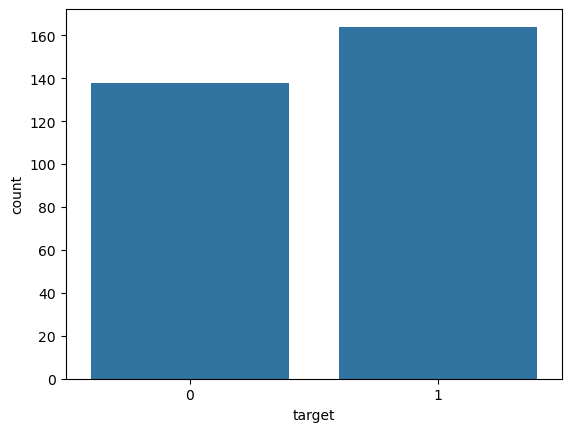

In [28]:
df.columns
sns.countplot(x='target',data=df)
plt.show()


Gender Distribution in Dataset 0-female, 1-male

In [26]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

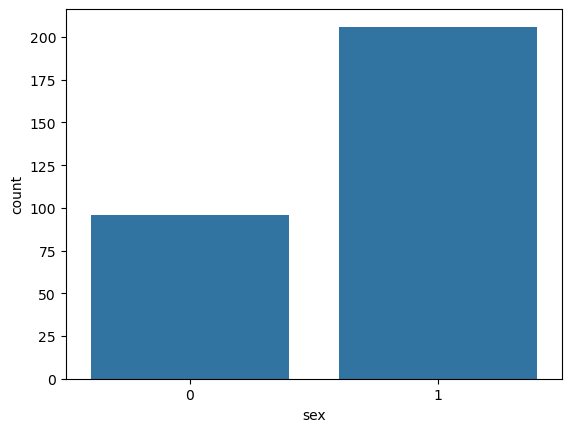

In [29]:
sns.countplot(x='sex',data=df)
plt.show()

<Axes: >

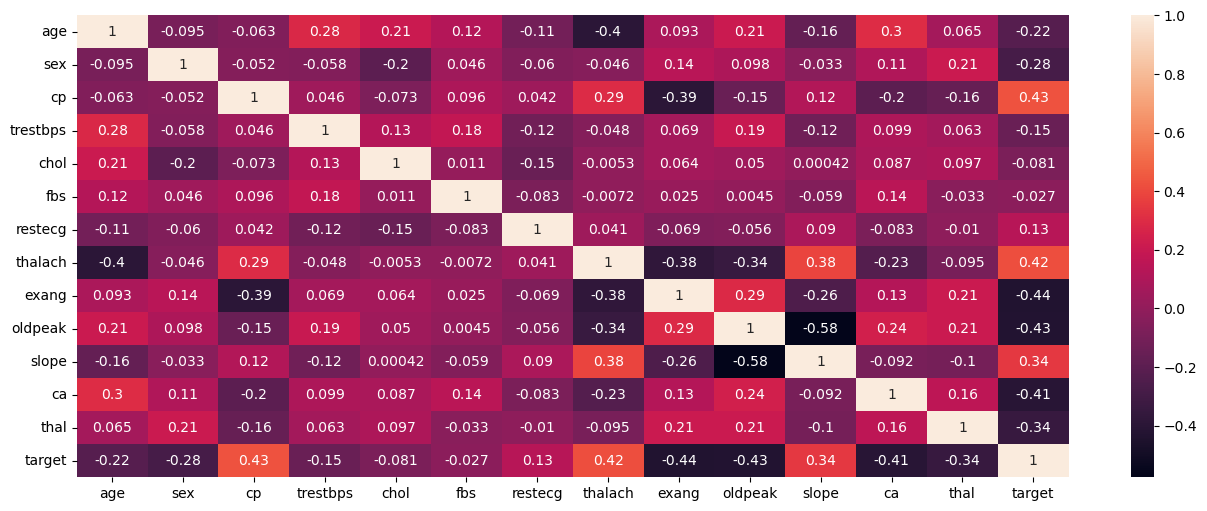

In [15]:
plt.figure(figsize=(16,6))
sns.heatmap(df.corr(),annot=True)


distribution of heart disease among male and females

In [30]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

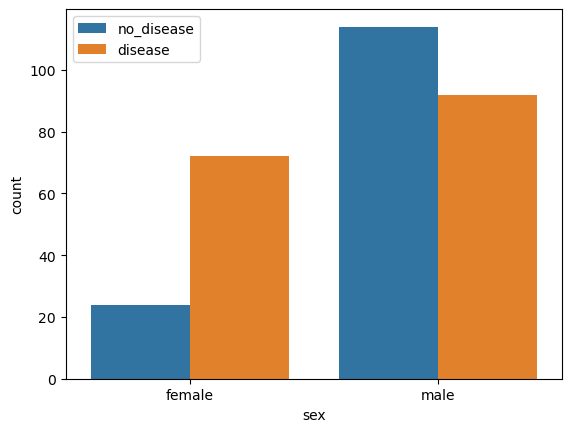

In [34]:
sns.countplot(data=df,x=df['sex'],hue=df['target'])
plt.xticks([0,1],['female','male'])
plt.legend(labels=['no_disease','disease'])
plt.show()

distribution of ages in our dataset histogram showes major responders lies between age 50_60

In [35]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

C:\Users\janak\AppData\Local\Temp\ipykernel_32276\1602346454.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['age'],bins=20)


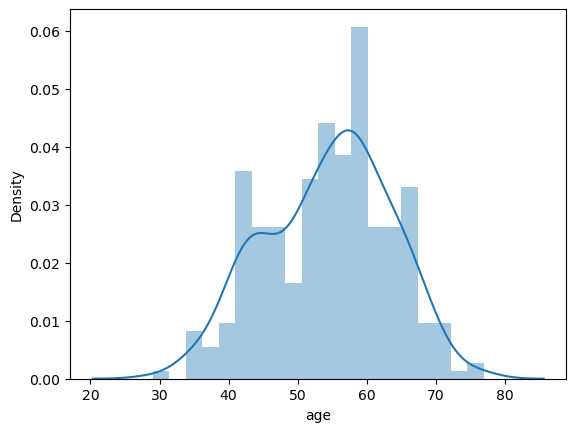

In [37]:
sns.distplot(df['age'],bins=20)
plt.show()

chest pain types

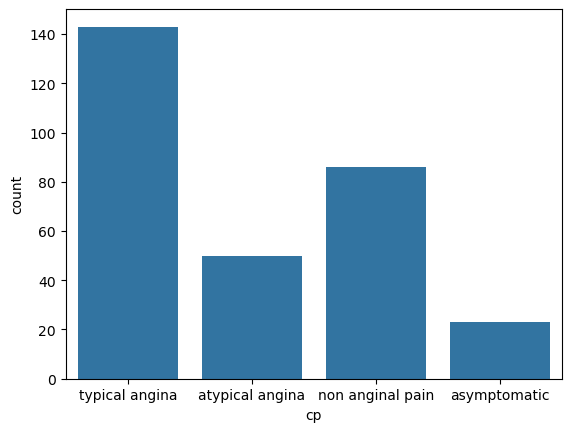

In [39]:
sns.countplot(x='cp',data=df)
plt.xticks([0,1,2,3],["typical angina","atypical angina","non anginal pain","asymptomatic"])
plt.show()

chest pain distribution in heart disease vs non heart disease

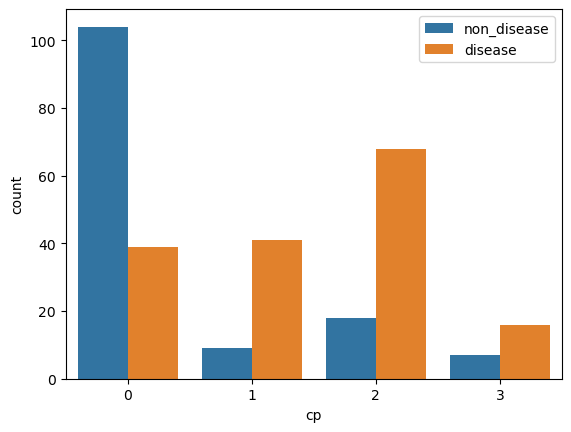

In [41]:
sns.countplot(data=df,x='cp',hue='target')
plt.legend(labels=["non_disease","disease"])
plt.show()

resting blood pressure overview if resting bp is high more changes of heart disease

In [42]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

<Axes: >

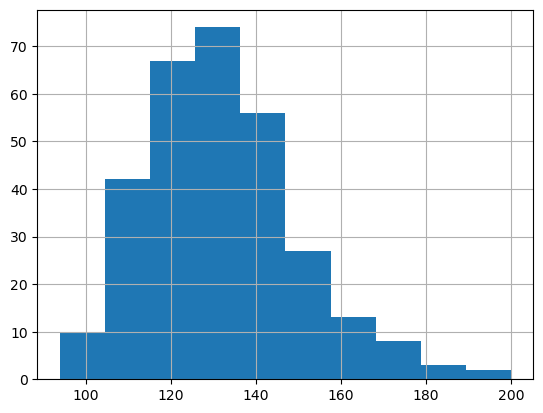

In [43]:
df['trestbps'].hist()

compare resting blood pressure as per sex column


C:\Users\janak\anaconda3\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  func(*plot_args, **plot_kwargs)
C:\Users\janak\anaconda3\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  func(*plot_args, **plot_kwargs)


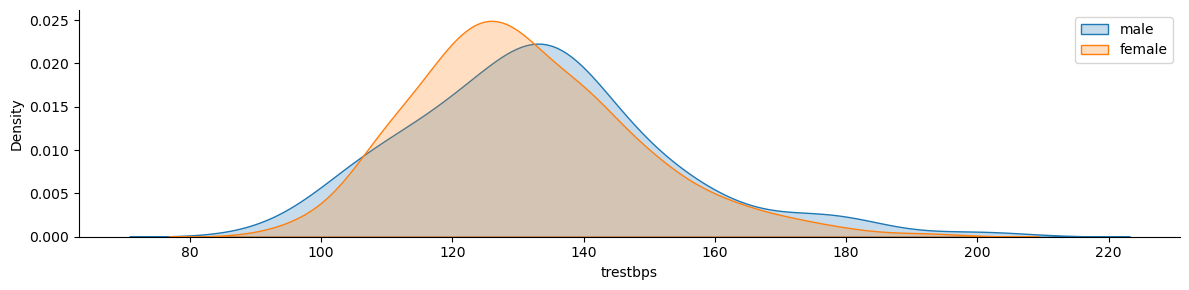

In [53]:
g=sns.FacetGrid(data=df,hue="sex",aspect=4)
g.map(sns.kdeplot,'trestbps',shade=True)
plt.legend(labels=['male','female'])                

serum cholesterol data distribution

<Axes: >

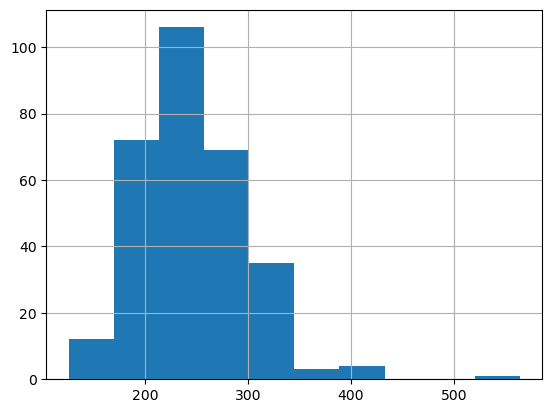

In [44]:
df['chol'].hist()

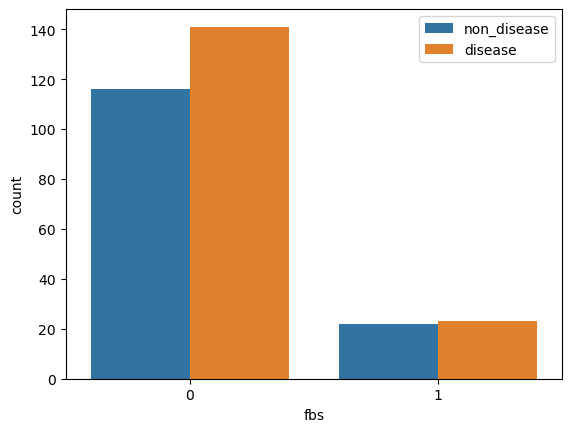

In [45]:
sns.countplot(data=df,x='fbs',hue='target')
plt.legend(labels=["non_disease","disease"])
plt.show()

C:\Users\janak\AppData\Local\Temp\ipykernel_32276\1676008464.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['No CVD', 'CVD Present'])


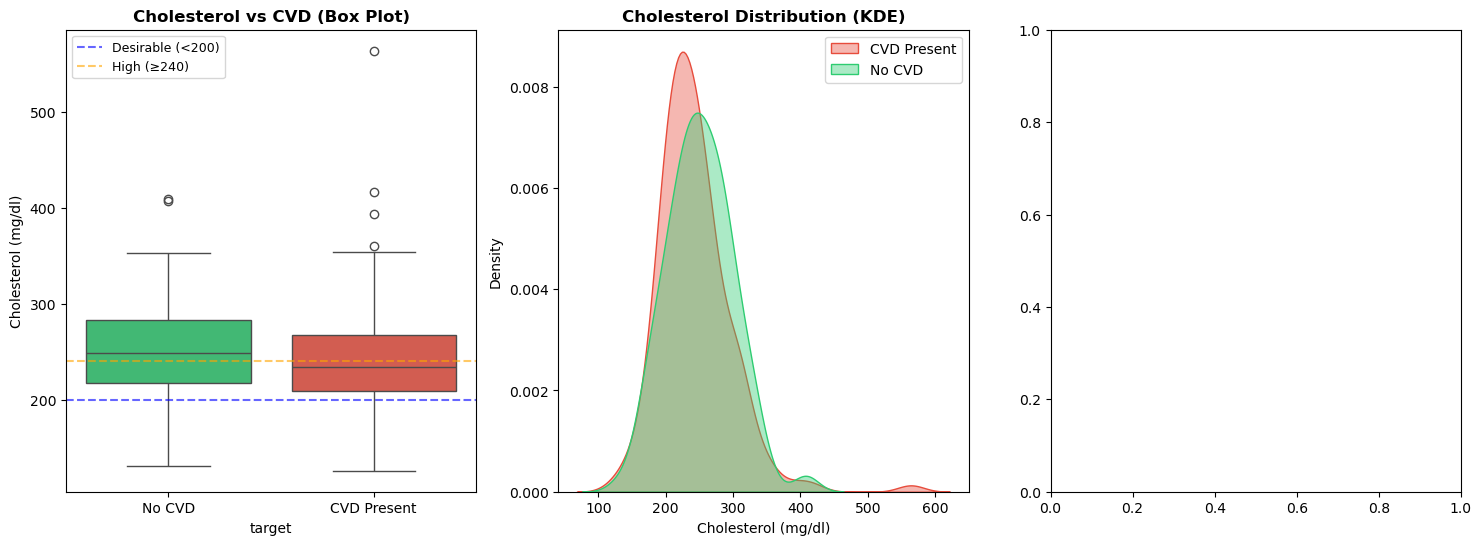

In [67]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# ── Plot 1: Box Plot ──────────────────────────────────────────────────────────
sns.boxplot(data=df, x='target', y='chol',
            hue='target',
            palette={0: '#2ecc71', 1: '#e74c3c'},
            legend=False, ax=axes[0])
axes[0].set_xticklabels(['No CVD', 'CVD Present'])
axes[0].set_title('Cholesterol vs CVD (Box Plot)', fontweight='bold')
axes[0].set_ylabel('Cholesterol (mg/dl)')
axes[0].axhline(200, color='blue',   linestyle='--', alpha=0.6, label='Desirable (<200)')
axes[0].axhline(240, color='orange', linestyle='--', alpha=0.6, label='High (≥240)')
axes[0].legend(fontsize=9)

# ── Plot 2: KDE Plot ──────────────────────────────────────────────────────────
sns.kdeplot(df[df['target']==1]['chol'], label='CVD Present',
            color='#e74c3c', fill=True, alpha=0.4, ax=axes[1])
sns.kdeplot(df[df['target']==0]['chol'], label='No CVD',
            color='#2ecc71', fill=True, alpha=0.4, ax=axes[1])
axes[1].set_title('Cholesterol Distribution (KDE)', fontweight='bold')
axes[1].set_xlabel('Cholesterol (mg/dl)')
axes[1].legend()


plot continuous variable

In [54]:
df.columns


Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [56]:
cate_val=[]
cont_val=[]
for column in df.columns:
    if df[column].nunique()<=10:
        cate_val.append(column)
    else:
        cont_val.append(column)

In [57]:
cate_val

['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target']

In [58]:
cont_val

['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

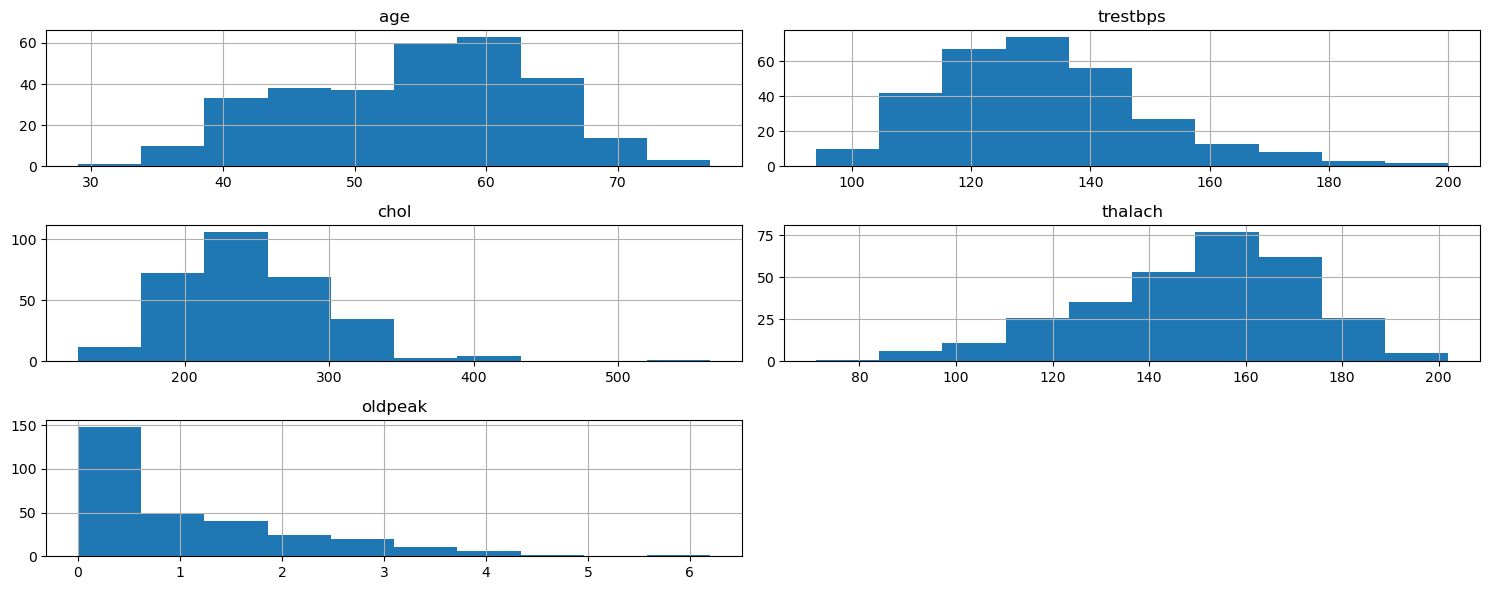

In [59]:
df.hist(cont_val,figsize=(15,6))
plt.tight_layout()
plt.show()

thalesemia and vascular factor

C:\Users\janak\AppData\Local\Temp\ipykernel_32276\2158743453.py:40: UserWarning: Glyph 129516 (\N{DNA DOUBLE HELIX}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\janak\AppData\Local\Temp\ipykernel_32276\2158743453.py:41: UserWarning: Glyph 129516 (\N{DNA DOUBLE HELIX}) missing from font(s) DejaVu Sans.
  plt.savefig("step11_thalassemia.png", dpi=150, bbox_inches='tight')
C:\Users\janak\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 129516 (\N{DNA DOUBLE HELIX}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


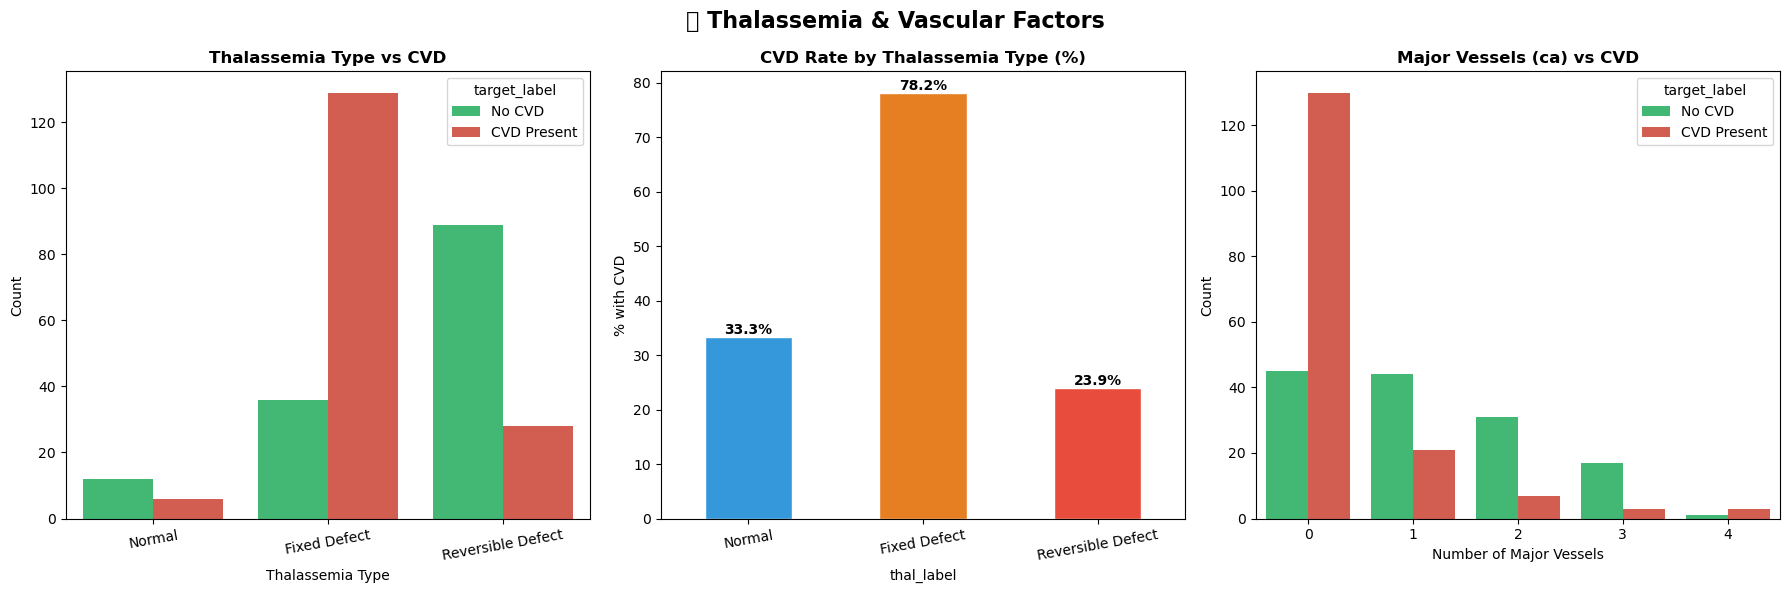

In [68]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Map thal labels
thal_labels = {1: 'Normal', 2: 'Fixed Defect', 3: 'Reversible Defect'}
df['thal_label'] = df['thal'].map(thal_labels)

# ── Plot 1: Thal count by CVD ─────────────────────────────────────────────────
thal_cvd = df.groupby(['thal_label', 'target']).size().reset_index(name='count')
thal_cvd['target_label'] = thal_cvd['target'].map({0: 'No CVD', 1: 'CVD Present'})
order_thal = ['Normal', 'Fixed Defect', 'Reversible Defect']
sns.barplot(data=thal_cvd, x='thal_label', y='count',
            hue='target_label', order=order_thal,
            palette=['#2ecc71', '#e74c3c'], ax=axes[0])
axes[0].set_title('Thalassemia Type vs CVD', fontweight='bold')
axes[0].set_xlabel('Thalassemia Type')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=10)

# ── Plot 2: CVD Rate per Thal type ────────────────────────────────────────────
thal_rate = df.groupby('thal_label')['target'].mean() * 100
thal_rate = thal_rate.reindex(order_thal)
thal_rate.plot(kind='bar', color=['#3498db', '#e67e22', '#e74c3c'],
               edgecolor='white', ax=axes[1], rot=10)
axes[1].set_title('CVD Rate by Thalassemia Type (%)', fontweight='bold')
axes[1].set_ylabel('% with CVD')
for i, v in enumerate(thal_rate):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')

# ── Plot 3: ca (vessels) vs CVD ───────────────────────────────────────────────
ca_cvd = df.groupby(['ca', 'target']).size().reset_index(name='count')
ca_cvd['target_label'] = ca_cvd['target'].map({0: 'No CVD', 1: 'CVD Present'})
sns.barplot(data=ca_cvd, x='ca', y='count',
            hue='target_label',
            palette=['#2ecc71', '#e74c3c'], ax=axes[2])
axes[2].set_title('Major Vessels (ca) vs CVD', fontweight='bold')
axes[2].set_xlabel('Number of Major Vessels')
axes[2].set_ylabel('Count')

plt.suptitle("🧬 Thalassemia & Vascular Factors", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig("step11_thalassemia.png", dpi=150, bbox_inches='tight')
plt.show()

In [71]:
# Heart disease rate for each thal value
print("Heart disease rate by thal value (%):\n",
      df.groupby("thal")["target"].mean().mul(100).round(1))

# Heart disease rate for each number of major vessels
print("Heart disease rate by number of major vessels (%):\n",
      df.groupby("ca")["target"].mean().mul(100).round(1))

# Heart disease rate for each chest pain type
print("Heart disease rate by chest pain type (%):\n",
      df.groupby("cp")["target"].mean().mul(100).round(1))


Heart disease rate by thal value (%):
 thal
0    50.0
1    33.3
2    78.2
3    23.9
Name: target, dtype: float64
Heart disease rate by number of major vessels (%):
 ca
0    74.3
1    32.3
2    18.4
3    15.0
4    75.0
Name: target, dtype: float64
Heart disease rate by chest pain type (%):
 cp
0    27.3
1    82.0
2    79.1
3    69.6
Name: target, dtype: float64


peak exercise vs heart attack

C:\Users\janak\AppData\Local\Temp\ipykernel_32276\2102041146.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['No CVD', 'CVD Present'])
C:\Users\janak\AppData\Local\Temp\ipykernel_32276\2102041146.py:34: UserWarning: Glyph 127939 (\N{RUNNER}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\janak\AppData\Local\Temp\ipykernel_32276\2102041146.py:35: UserWarning: Glyph 127939 (\N{RUNNER}) missing from font(s) DejaVu Sans.
  plt.savefig("step10_exercise.png", dpi=150, bbox_inches='tight')
C:\Users\janak\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127939 (\N{RUNNER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


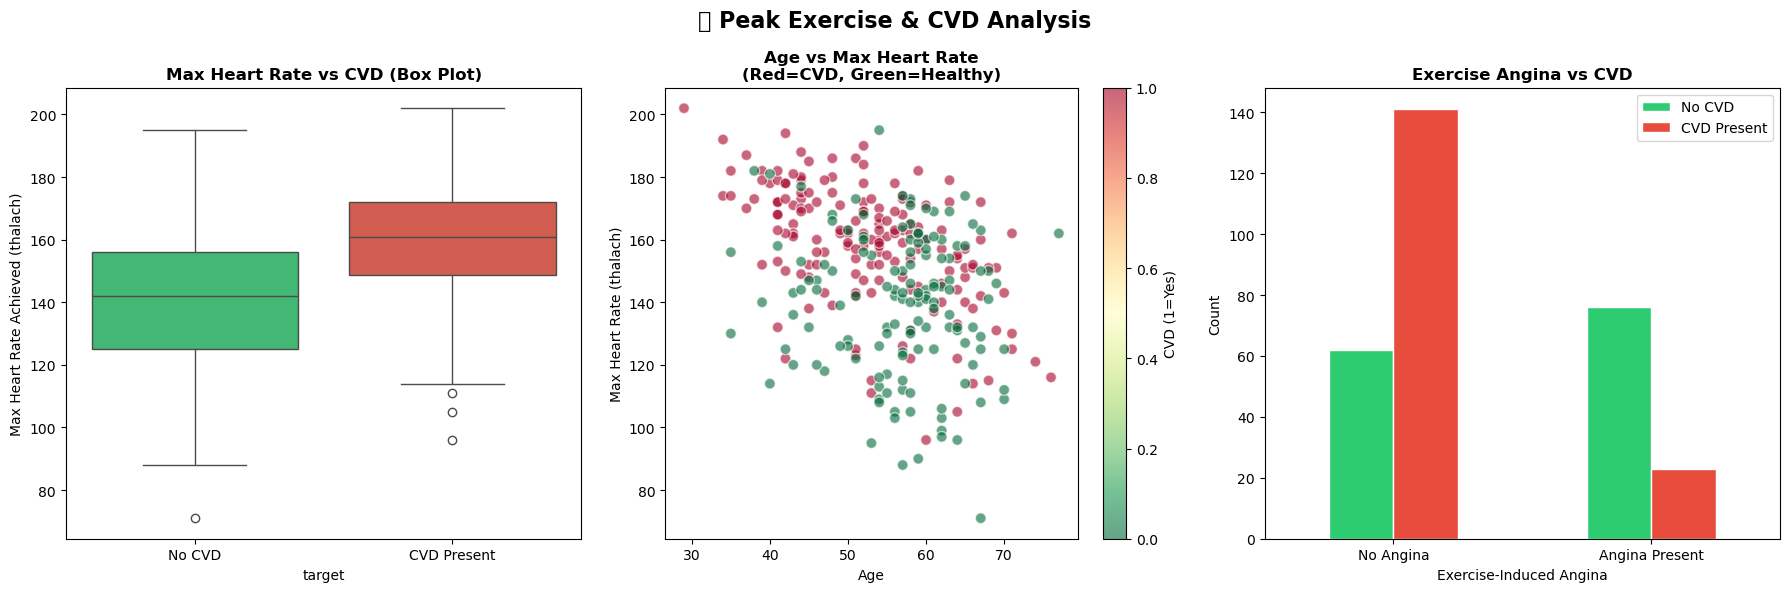

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# ── Plot 1: Box Plot ──────────────────────────────────────────────────────────
sns.boxplot(data=df, x='target', y='thalach',
            hue='target',
            palette={0: '#2ecc71', 1: '#e74c3c'},
            legend=False, ax=axes[0])
axes[0].set_xticklabels(['No CVD', 'CVD Present'])
axes[0].set_title('Max Heart Rate vs CVD (Box Plot)', fontweight='bold')
axes[0].set_ylabel('Max Heart Rate Achieved (thalach)')

# ── Plot 2: Scatter — Age vs thalach coloured by target ──────────────────────
scatter2 = axes[1].scatter(df['age'], df['thalach'],
                           c=df['target'], cmap='RdYlGn_r',
                           alpha=0.6, edgecolors='white', s=60)
axes[1].set_title('Age vs Max Heart Rate\n(Red=CVD, Green=Healthy)', fontweight='bold')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Max Heart Rate (thalach)')
plt.colorbar(scatter2, ax=axes[1], label='CVD (1=Yes)')


# ── Plot 3: Exercise-Induced Angina (exang) stacked bar ───────────────────────
exang_cvd = df.groupby(['exang', 'target']).size().unstack()
exang_cvd.index = ['No Angina', 'Angina Present']
exang_cvd.columns = ['No CVD', 'CVD Present']
exang_cvd.plot(kind='bar', stacked=False,
               color=['#2ecc71', '#e74c3c'],
               ax=axes[2], edgecolor='white', rot=0)
axes[2].set_title('Exercise Angina vs CVD', fontweight='bold')
axes[2].set_xlabel('Exercise-Induced Angina')
axes[2].set_ylabel('Count')

plt.suptitle("🏃 Peak Exercise & CVD Analysis", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig("step10_exercise.png", dpi=150, bbox_inches='tight')
plt.show()


Heart disease rate by exercise-induced angina (%):
 exang
0    69.5
1    23.2
Name: target, dtype: float64


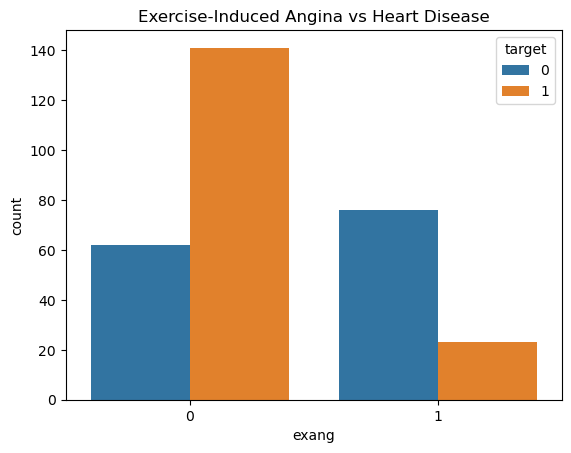

In [72]:
# Heart disease rate for people with/without exercise-induced angina
print("Heart disease rate by exercise-induced angina (%):\n",
      df.groupby("exang")["target"].mean().mul(100).round(1))

# Plot
sns.countplot(x="exang", hue="target", data=df)
plt.title("Exercise-Induced Angina vs Heart Disease")
plt.show()


pair plot (all variable)

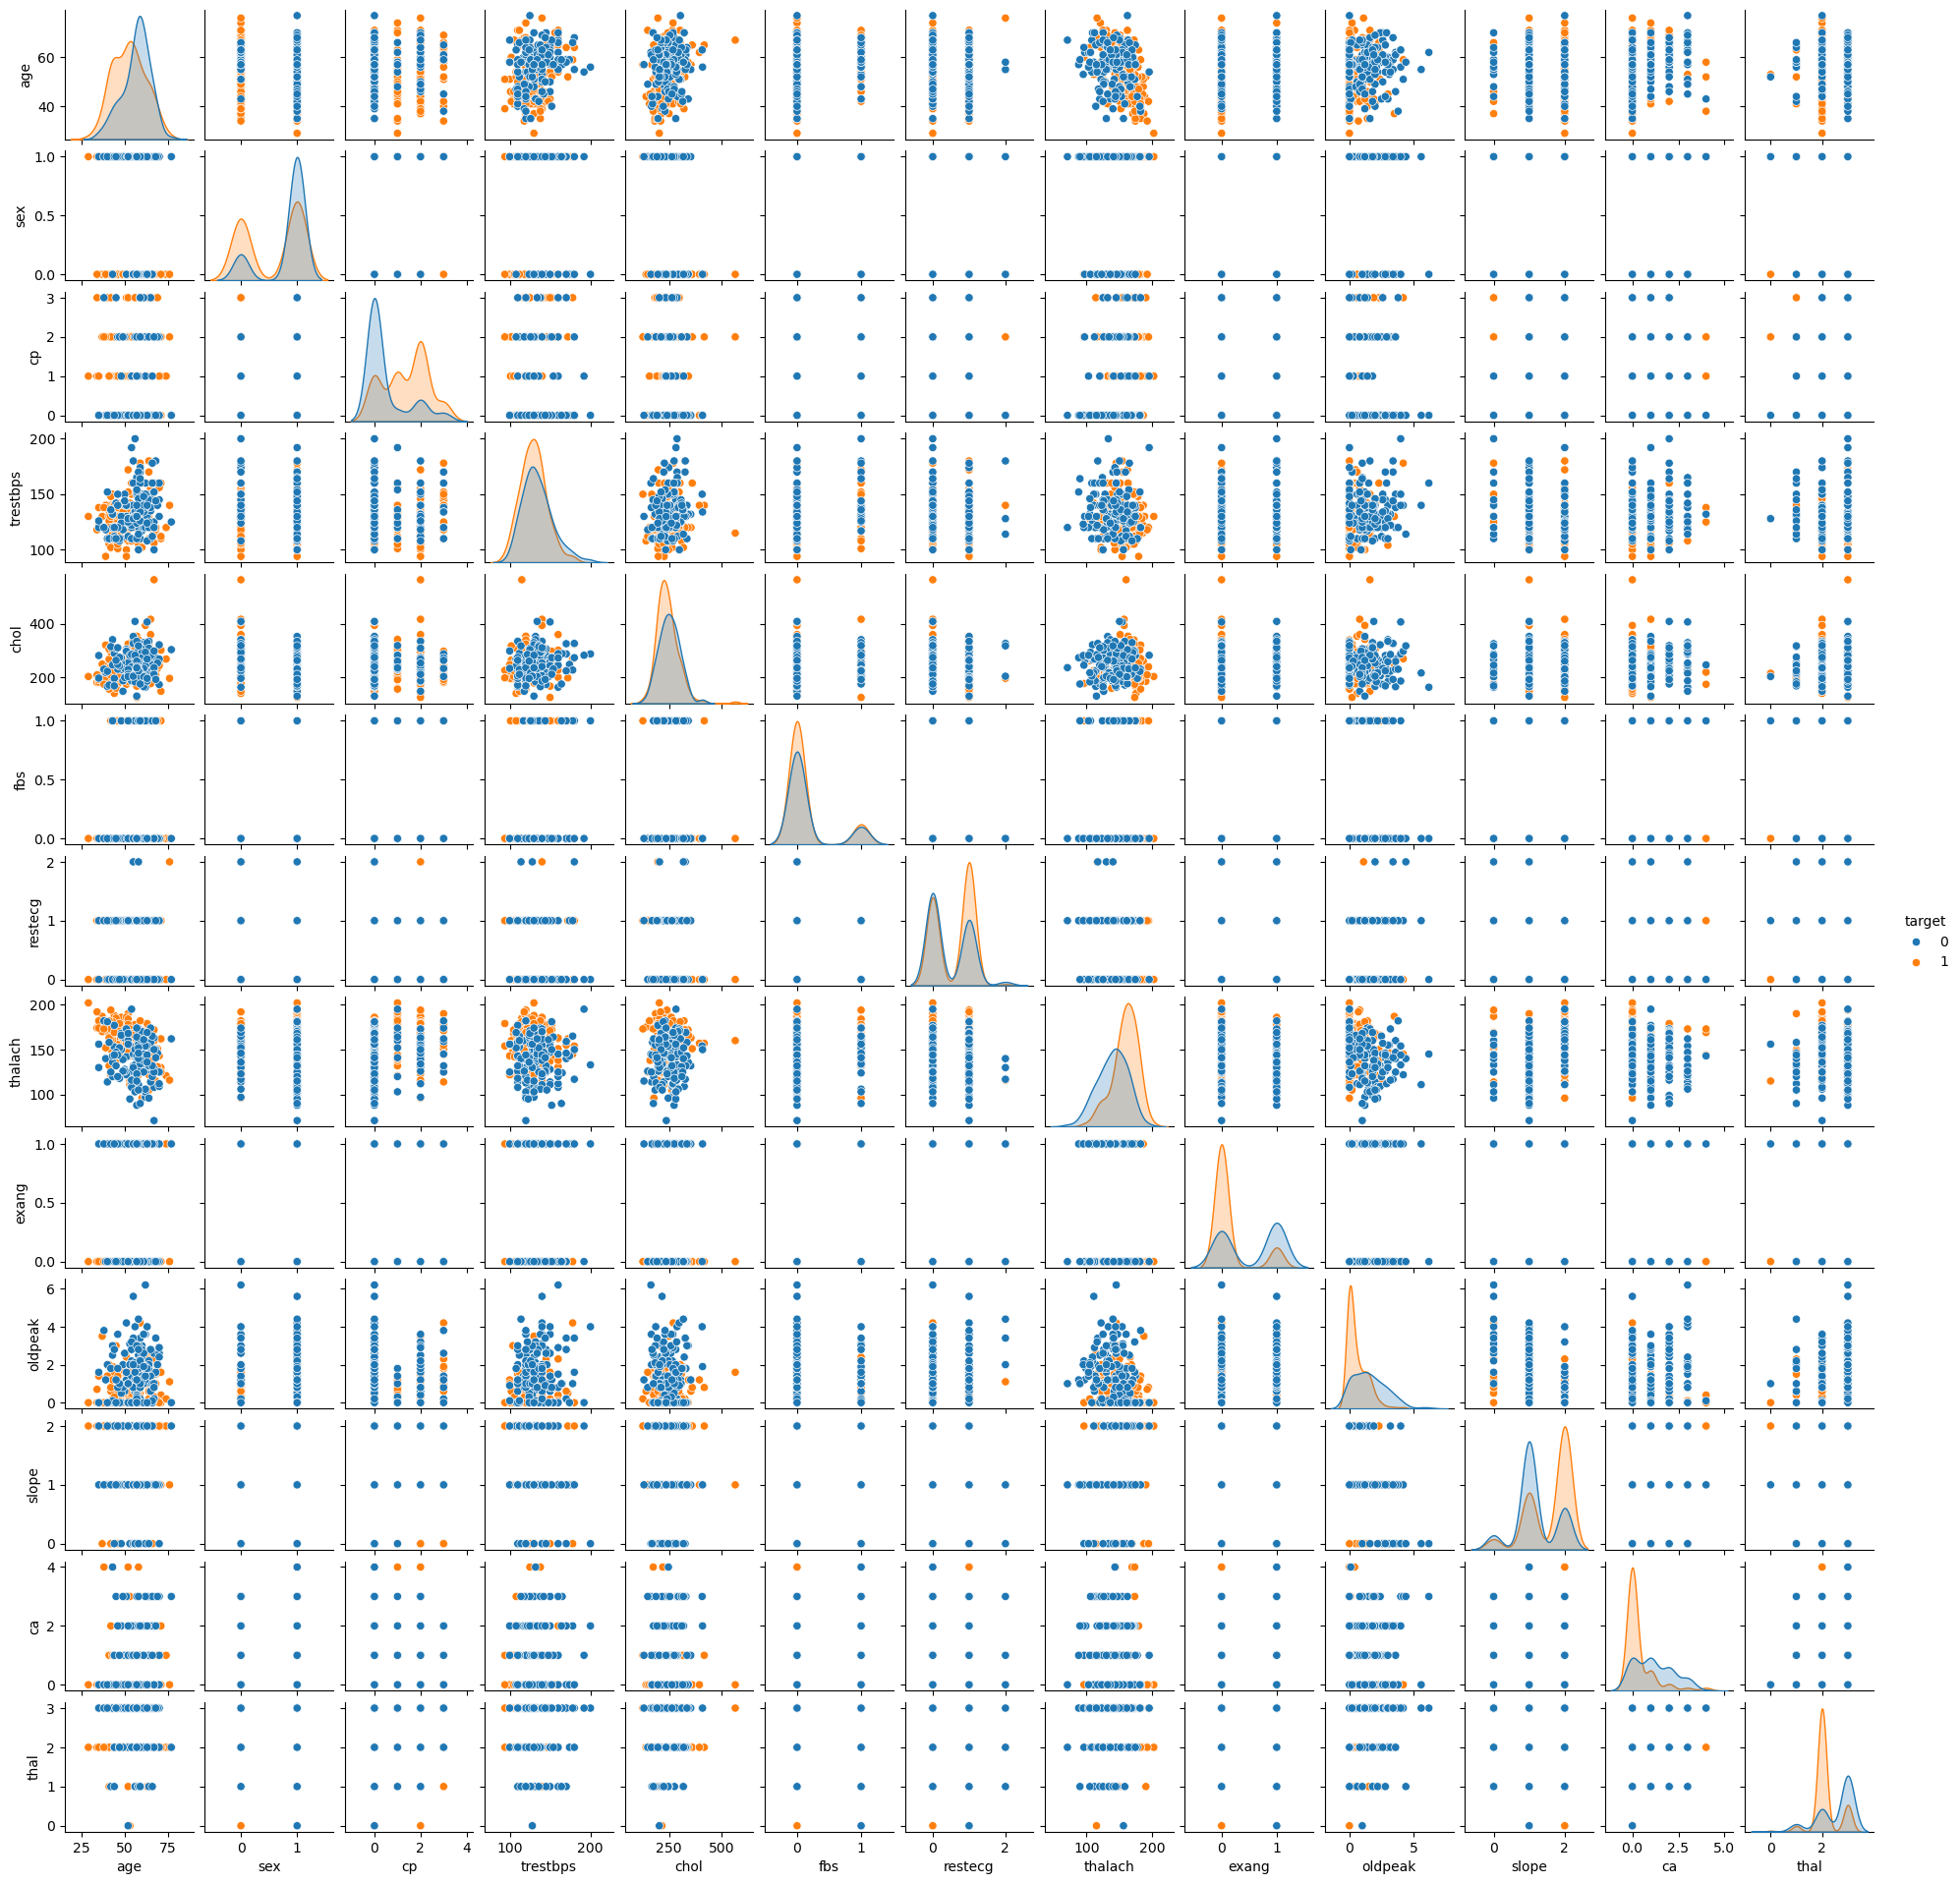

In [73]:
original_cols = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                 "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]

sns.pairplot(df[original_cols], hue="target", height=1.5)
plt.show()


In [ ]:
RESULT
AGE-MOST COMMON PATIENTS LIES BETWEEN AGE OF 50_60
GENDER-MORE COMMON IN MALE
BLOOD PRESSURE-HYPERTENSIVE PATIENT HAVE MORE CHANCES
ST DEPRESSION-HIGHER AVG DEPRESSION
CHOLESTEROL-HIGHER CHOLESTEROL CHANCES ARE MORE
CHEST PAIN TYPES-NON ANGINAL PAIN
EXERCISE INDUCED ANGINA VS HEART DISEASE